# Card castle

Loads `outputs/card_castle/` and shows where the arm goes: a house of cards between the tip
and its target, one spring pulling toward the target, one Gaussian pushing off the castle when
the field is on. Without the field the tip drives straight through the cards; with it, the field
deflects the tip, which slides round the castle (the standoff the demo was designed for is a
saddle, see the folder's README). Scripted end to end (`castle_demo.py`), nothing dragged by hand.

Position and strength are read from the run itself, never the config.

Two figures: the backbone at each condition's steady pose, X-Y above X-Z, against the castle
and the target beyond it; and the tip's X-Y path on its way there. Every panel is drawn at
equal scale (10 cm in Y is 10 cm in X), so the Gaussian's sigma circle is a circle.
Each figure is saved with its legend as a separate figure (`*_legend`), so the plots hold only data.

Older runs carry a smaller field set; the cells below adapt to what's present.


In [1]:
import sys, os, importlib.util
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_1P5, FIG_W_DOUBLE, set_font_size, fit_equal_scale, legend_figure
from FK_Multi import FK_Multi
from VMC_utils.ConfigHelpers import strip_repeat

# plot_config.py's COLORS is the repo-wide pastel palette (a later, unrelated
# change) -- but every figure already saved in this notebook was built with
# the ORIGINAL vivid "npg" palette (before that pastel-ization), so importing
# today's COLORS and re-running would silently repaint every existing plot
# here pastel. Overriding it locally keeps this notebook's figures matching
# what's already saved, independent of whatever plot_config.py defaults to
# later.
COLORS = ['#1B9E77', '#D95F02', '#7570B3', '#E7298A']

GRID = False
FONT_SIZE = 28
LINE_SCALE = 1.5   # TUNE THIS: thickness of the lines inside the plots (data lines, arrows, sigma circle); 1 = the original
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

import glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerLine2D

G_TO_N = 9.80665e-3   # load cell reports grams
S_BACKBONE = np.linspace(0.0, 1.0, 25)
SETTLE_S = 1.0        # [s] dropped from the front of a hold window, to let the arm arrive


def save_fig(fig, folder, name):
    """Every figure as PDF and SVG, next to the runs it came from.

    Saved at the figure's own size, not re-cropped (the shared style's savefig.bbox is
    'tight', which would trim the page to the ink): the width set in a cell is the width
    of the file, and the height follows from it."""
    with plt.rc_context({'savefig.bbox': 'standard'}):
        for ext in ('pdf', 'svg'):
            fig.savefig(os.path.join('outputs', folder, f'{name}.{ext}'))


LEGEND_LINE_LENGTH = 1.2   # TUNE THIS: height of a legend entry's handle, in font sizes: the vertical lines fill it


class HandlerVLine(HandlerLine2D):
    """Legend handle for a plotted line: a VERTICAL stroke in its colour, centred in the handle
    box where the star and cross markers sit. Marker-only handles are drawn as usual."""

    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        if orig_handle.get_linestyle() in ('None', 'none', ' ', ''):
            return super().create_artists(legend, orig_handle, xdescent, ydescent, width, height,
                                          fontsize, trans)
        x = 0.5 * width - 0.5 * xdescent   # the column the star and cross markers are centred in
        stroke = Line2D([x, x], [-ydescent, height - ydescent])   # the whole handle box, bottom to top
        self.update_prop(stroke, orig_handle, legend)
        stroke.set_solid_capstyle('butt')   # ends exactly at the handle box, however thick the line
        stroke.set_transform(trans)
        return [stroke]


def save_legend(ax, folder, name, fontsize, ncol):
    """`ax`'s legend as a figure of its own, saved next to its plot as <name>_legend.

    The plot itself carries no legend, so it holds only data, and nothing has to be made
    room for. Built from the plot's own handles and labels, so the two cannot disagree.
    The coloured lines are drawn vertical (HandlerVLine)."""
    fig = legend_figure(*ax.get_legend_handles_labels(), fontsize=fontsize, ncol=ncol,
                        handler_map={Line2D: HandlerVLine()}, handleheight=LEGEND_LINE_LENGTH,
                        handlelength=1.0)   # a vertical stroke needs no long handle
    save_fig(fig, folder, name + '_legend')
    return fig


def nice(label):
    """Legend-ready text: no underscores, starts with a capital letter."""
    return label.replace('_', ' ').capitalize()

In [2]:
def load_cfg(name):
    """Import a config variant by file name without copying it into place."""
    spec = importlib.util.spec_from_file_location('cfg_' + name, f'GUI_MultiVMC_Config_{name}.py')
    mod  = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


def list_runs(folder):
    """Every run recorded in outputs/<folder>/, by name.

    A run that didn't exit cleanly can leave `<run>.autosave.npz` (last 30 s
    checkpoint, readable) or `<run>.npz.part.npz` (truncated, skipped)."""
    names = []
    for path in sorted(glob.glob(os.path.join('outputs', folder, '*.npz'))):
        name = os.path.splitext(os.path.basename(path))[0]
        if name.endswith('.part'):
            print(f'[skip] {name}.npz -- interrupted write, not readable')
            continue
        if name.endswith('.autosave'):
            print(f'[note] {name}.npz is a checkpoint: the run did not exit cleanly, '
                  'so it ends at the last one taken')
        names.append(name)
    return names


def hold_window(d, tol=1e-9, settle=SETTLE_S, mark_index=0):
    """The measurement window.

    With an operator mark (Ctrl+C when the tip reached the button), the window
    starts there and runs until something moves again; `mark_index` picks which
    mark. Without one, falls back to the longest stretch where nothing moved
    (goal x/y, spring/damper params) -- can't tell "on the button" from "let go
    of the mouse", and can span a mid-run stiffness change.

    Goal z is excluded from the motion check: in `_person`/`_card_castle`
    (GOAL_Z_TRACK) it re-tracks the attachment point every tick and wiggles at
    ~1e-5 m from FK noise even when still, which fragmented the hold into single
    ticks. `_button`'s locked z is unaffected either way.

    Drops the first SETTLE_S so the arm's arrival isn't averaged in."""
    t   = d['t']
    sig = [d['goal'][:, :, :2].reshape(len(t), -1), d['k_params']]
    if 'c_params' in d:
        sig.append(d['c_params'])
    sig = np.hstack([np.asarray(s, dtype=float) for s in sig])

    changed = np.r_[True, np.abs(np.diff(sig, axis=0)).max(axis=1) > tol]
    seg     = np.cumsum(changed)

    marks = np.asarray(d.get('marks_t', []), dtype=float)
    marks = marks[np.isfinite(marks) & (marks >= t[0]) & (marks <= t[-1])]
    if len(marks) > mark_index:
        m0   = marks[mark_index]
        hold = (seg == seg[int(np.searchsorted(t, m0))]) & (t >= m0)
    else:
        hold = seg == np.bincount(seg).argmax()

    trimmed = hold & (t >= t[hold][0] + settle) if hold.any() else hold
    return trimmed if trimmed.any() else hold   # a mark right before Ctrl+C


def load_run(folder, name):
    """One run: hold window marked, newer log channels passed through when present."""
    raw = np.load(os.path.join('outputs', folder, name + '.npz'), allow_pickle=True)
    d   = {k: raw[k] for k in raw.files}   # forces the read now, not lazily

    hold     = hold_window(d)
    tip_goal = d['goal'][:, 0, :]
    k_gauss  = d['k_params'][:, 1]

    r = dict(name=name, folder=folder, raw=d, t=d['t'], hold=hold,
             goal=d['goal'], comp_pos=d['comp_pos'],
             q_motor=d['q_motor'], tau=d['tau'],
             k_params=d['k_params'], k_gauss=k_gauss,
             force_n=d['force'] * G_TO_N,
             s_params=d['comp_s_params'],
             comp_names=[str(n) for n in d['comp_names']],
             tau_limit=float(d['tau_limit'][0]),
             strength=float(k_gauss[hold].mean()),
             target=tip_goal[hold].mean(axis=0),
             obstacle=d['goal'][hold, 1, :].mean(axis=0))

    # ── Channels only newer runs carry ────────────────────────────────────────
    r['f_comp']    = d.get('f_comp')            # (n, N_VC, 3) [N] per element
    r['comp_vel']  = d.get('comp_vel')          # (n, N_VC, 3) [m/s]
    r['c_params']  = d.get('c_params')
    r['force_age'] = d.get('force_age')
    r['tau_raw']   = d.get('tau_raw', d['tau'])  # pre-limiter torque, else the clipped one
    r['clipped']   = np.any(np.abs(r['tau_raw']) > r['tau_limit'] + 1e-12, axis=1)
    r['has_pre']   = bool((d['t'] < 0).any())    # logged before the GUI connected
    r['force_live'] = bool(np.any(d['force'] != 0.0))
    # Group repeats by condition (button: `weak_r1..r5`); a person/card_castle
    # run is one file per level, so it's its own group.
    r['condition']   = strip_repeat(name)
    r['repeat']      = name[len(r['condition']):].lstrip('_') or None
    r['marks_t']     = np.asarray(d.get('marks_t', []), dtype=float)
    r['marks_label'] = [str(x) for x in d.get('marks_label', [])]
    return r


def backbone(run, hold=None):
    """FK backbone at the mean pose over a window (the hold window by default)."""
    mask = run['hold'] if hold is None else hold
    q_ss = run['q_motor'][mask].mean(axis=0)
    return np.array([FK_Multi(q_ss, s)[:3] for s in S_BACKBONE])


def load_all(folder):
    """Every readable run in a folder; one bad file doesn't stop the rest."""
    runs = []
    for name in list_runs(folder):
        try:
            runs.append(load_run(folder, name))
        except Exception as exc:
            print(f'[skip] {name}.npz -- {type(exc).__name__}: {exc}')
    # Sweep order, not alphabetical -- `medium_r1` would sort before `no_gauss_r1`
    # and reverse the legend. Runs at one strength (person/card_castle) just sort by name.
    return sorted(runs, key=lambda r: (r['strength'], r['name']))

In [3]:
cfg_c  = load_cfg('card_castle')
runs_c = load_all('card_castle')
if not runs_c:
    print('outputs/card_castle/ is empty -- record the two cases first '
          '(README: --run gauss first, then rebuild and --run no_gauss).')
else:
    missing = [c for c in cfg_c.GAUSS_CONDITIONS if c not in {r['name'] for r in runs_c}]
    if missing:
        print('[note] not recorded yet: ' + ', '.join(missing))

### Geometry

The backbone at each condition's steady pose, X-Y above X-Z sharing the X axis, against the
castle and the target beyond it. Every axis is at the same scale (10 cm is the same length on X, Y and Z); only the width is set, the height follows from the data.
The legend is a separate figure (`backbone_legend`), so the plot itself holds only data.

In [4]:
GEOMETRY_WIDTH = FIG_W_1P5   # in -- TUNE THIS: figure width -- the only size set here: the height
                             # follows from it, every panel at the same scale (equal axes)
GEOMETRY_LEGEND_FONT = 15   # TUNE THIS: legend text size (the legend is its own figure, `backbone_legend`)
GEOMETRY_LEGEND_NCOL = 1   # TUNE THIS: legend columns: 1 stacks the entries, 3 or more lays them in a row
GEOMETRY_XLIM_UPPER = 25   # cm -- TUNE THIS: upper X limit, shared by both panels
GEOMETRY_XY_YTOP = 55   # TUNE THIS: top panel's Y upper limit -- autoscale was clipping the Target star

def draw_target_obstacle(ax, tgt, obs, sigma, v, obstacle_label, labelled=True):
    """Target star, obstacle cross and the Gaussian's sigma circle, in the (X, v) plane
    (v = 1 for Y, 2 for Z). One place, so every figure draws them the same way.

    sigma is where the Gaussian's force peaks. In X-Y it is the field's true
    cross-section: goal z tracks the attachment point's z, so the field is a
    cylinder along z and only the lateral distance counts. In X-Z the circle is
    a reference only -- the obstacle's and target's z are not coordinates."""
    ax.plot(tgt[0] * 100, tgt[v] * 100, '*', color='k', markersize=13, zorder=5,
            label='Anchor point' if labelled else None)
    ax.plot(obs[0] * 100, obs[v] * 100, 'X', color='k', markersize=9, zorder=5,
            label=nice(obstacle_label) if labelled else None)
    ax.add_patch(plt.Circle((obs[0] * 100, obs[v] * 100), sigma * 100, fill=False,
                            linestyle='--', color='k', linewidth=0.9 * LINE_SCALE, alpha=0.5, zorder=2))


def plot_geometry(runs, cfg, folder, obstacle_label='obstacle', name='backbone'):
    obs = runs[0]['obstacle']
    tgt = runs[0]['target']

    # Top view (X-Y) directly above the side view (X-Z), sharing the X axis --
    # same layout as plot_person.ipynb.
    fig, (ax_xy, ax_xz) = plt.subplots(
        2, 1, figsize=(GEOMETRY_WIDTH, 4), sharex=True)   # height: set by fit_equal_scale, below

    conds = sorted({r['condition'] for r in runs},
                   key=lambda c: next(x['strength'] for x in runs if x['condition'] == c))
    for cond in conds:
        strength = next(r['strength'] for r in runs if r['condition'] == cond)
        print(f"{nice(cond)}: {strength:.0f} N/m")

    seen = set()
    for r in runs:
        i   = conds.index(r['condition'])          # colour by condition, not by file
        b   = backbone(r)
        lbl = None if r['condition'] in seen else (
            'No gaussian' if r['condition'] == 'no_gauss' else 'Gaussian')
        seen.add(r['condition'])
        ax_xy.plot(b[:, 0] * 100, b[:, 1] * 100, color=COLORS[i], linewidth=2.0 * LINE_SCALE,
                   alpha=0.85, zorder=3, label=lbl)
        ax_xz.plot(b[:, 0] * 100, b[:, 2] * 100, color=COLORS[i], linewidth=2.0 * LINE_SCALE,
                   alpha=0.85, zorder=3)
        for s in r['s_params'][1:]:            # the Gaussian attachment points
            p = b[np.argmin(np.abs(S_BACKBONE - s))]
            ax_xy.plot(p[0] * 100, p[1] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)
            ax_xz.plot(p[0] * 100, p[2] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)

    for a, v, vl in ((ax_xy, 1, 'Y (cm)'), (ax_xz, 2, 'Z (cm)')):
        draw_target_obstacle(a, tgt, obs, cfg.SIGMA, v, obstacle_label, labelled=a is ax_xy)
        a.set_ylabel(vl)
        a.grid(GRID)

    ax_xy.set_ylim(top=GEOMETRY_XY_YTOP)   # autoscale margin was clipping the star marker
    ax_xz.set_xlim(right=GEOMETRY_XLIM_UPPER)   # X is shared: both panels

    ax_xz.invert_yaxis()   # Z points down the page: 0 at top, positive Z below
    ax_xz.set_xlabel('X (cm)')
    ax_xy.set_xlabel('X (cm)')
    ax_xy.tick_params(labelbottom=True)   # sharex hides these by default

    # Equal scale on every axis of both panels, at the chosen width: 10 cm is the same
    # length on the page along X, Y and Z, so the sigma circle is a circle. Last, so it
    # sees the final limits and labels; it sets the figure height too. The panels hold
    # only data: the legend is a figure of its own.
    fit_equal_scale(fig, (ax_xy, ax_xz), GEOMETRY_WIDTH)

    save_fig(fig, folder, name)
    save_legend(ax_xy, folder, name, GEOMETRY_LEGEND_FONT, GEOMETRY_LEGEND_NCOL)
    plt.show()

No gauss: 0 N/m
Gauss: 1500 N/m


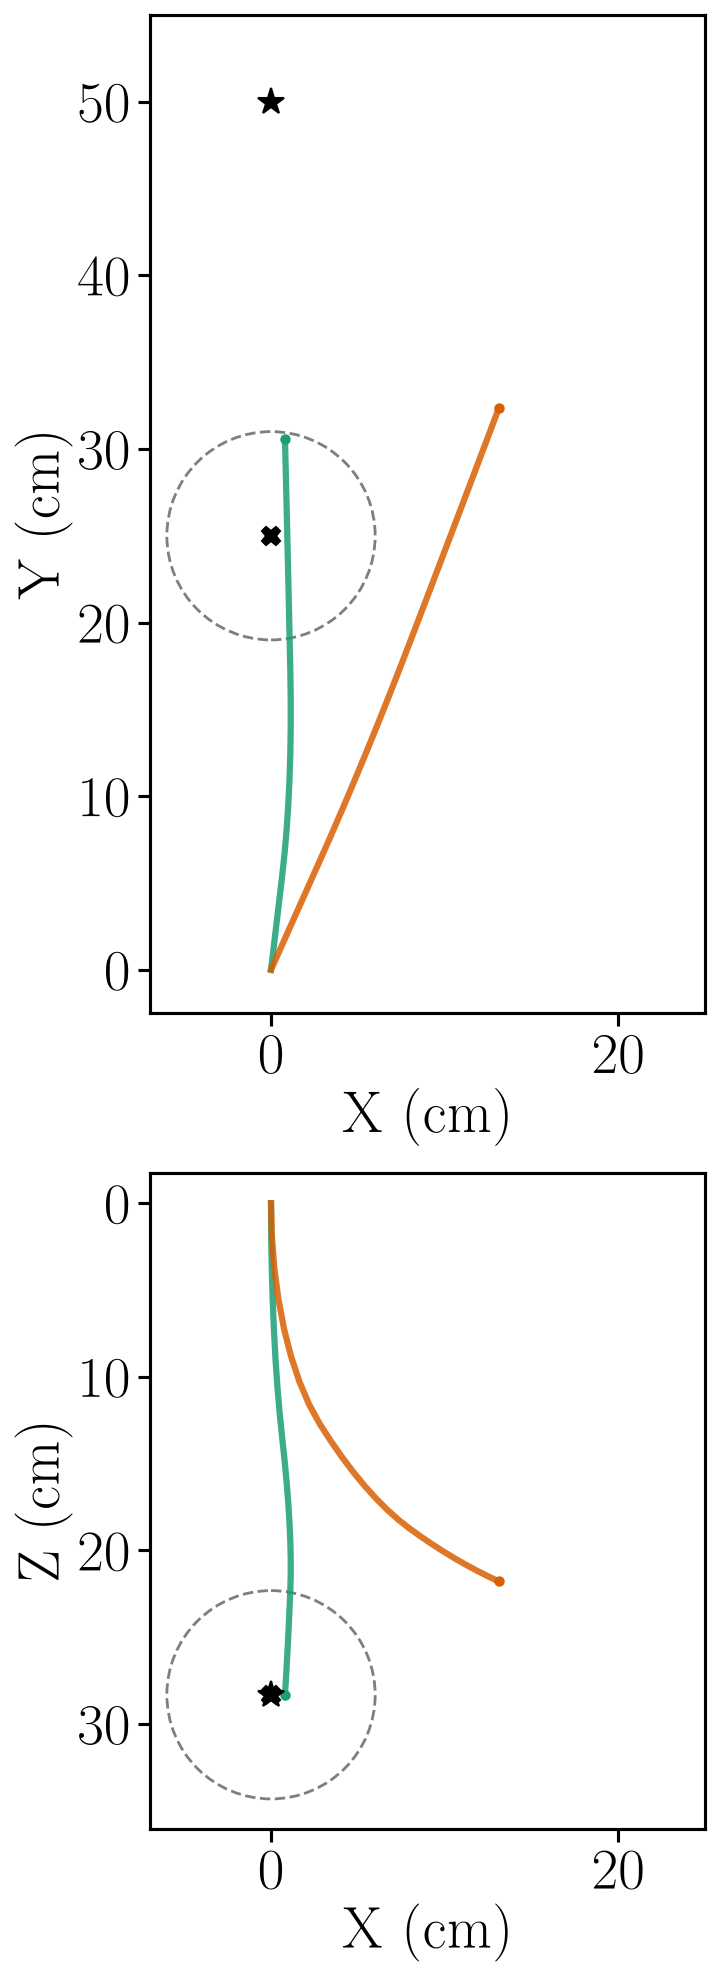

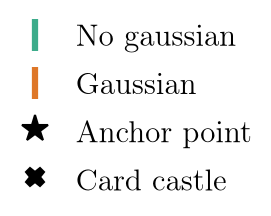

In [5]:
if runs_c:
    plot_geometry(runs_c, cfg_c, 'card_castle', obstacle_label='card castle')


### Tip trajectory

The tip's path in X-Y, from `t = 0` to the end of the run: forward kinematics on the logged motor
angles (the same as the logged tip position), with an arrowhead every few centimetres travelled
pointing the way it went, and a dot where it settles. Target, obstacle and the Gaussian's sigma
circle come from the same helper as the geometry figure above, so they are drawn identically.
The circle is the field's true cross-section here: the goal's z tracks the attachment point, so
only the X-Y distance counts.
Equal scale on both axes; only the width is set, the height follows from the data.
The legend is a separate figure (`tip_trajectory_legend`), so the plot itself holds only data.

In [6]:
TRAJ_WIDTH = FIG_W_1P5   # in -- TUNE THIS: figure width -- the only size set here (equal axes set the height)
TRAJ_LEGEND_FONT = 15   # TUNE THIS: legend text size (the legend is its own figure, `tip_trajectory_legend`)
TRAJ_LEGEND_NCOL = 1   # TUNE THIS: legend columns: 1 stacks the entries, 3 or more lays them in a row
TRAJ_XLIM_UPPER = 25   # cm -- TUNE THIS: upper X limit
TRAJ_ARROW_EVERY = 8.0   # cm -- TUNE THIS: path length travelled between arrowheads
TRAJ_ARROW_SIZE = 14   # TUNE THIS: arrowhead size (at LINE_SCALE = 1; it follows LINE_SCALE)
TRAJ_MIN_STEP = 0.25   # cm -- the tip only counts as travelling once it is this far from the last kept sample

def tip_path(run):
    """The tip's X-Y path [cm]: forward kinematics on the logged motor angles, t >= 0 to the end.

    Equal to the logged `comp_pos[:, 0]` (the tip is element 0, s = 1); done here so it is FK by construction."""
    q = run['q_motor'][run['t'] >= 0]
    return np.array([FK_Multi(qi, 1.0)[:2] for qi in q]) * 100

def draw_path_arrows(ax, xy, color):
    """An arrowhead every TRAJ_ARROW_EVERY cm travelled, pointing the way the tip went.

    Spaced by distance, not time, so the tip sitting still (the start, the final hold) gets none;
    motion below TRAJ_MIN_STEP is sensor jitter and doesn't count as travel."""
    kept = [0]
    for i in range(1, len(xy)):
        if np.hypot(*(xy[i] - xy[kept[-1]])) >= TRAJ_MIN_STEP:
            kept.append(i)
    p    = xy[kept]
    s    = np.r_[0.0, np.cumsum(np.hypot(*np.diff(p, axis=0).T))]   # distance travelled at each kept sample
    span = 0.5   # cm either side of the arrowhead, whose two ends give its direction
    for s0 in np.arange(TRAJ_ARROW_EVERY / 2, s[-1] - span, TRAJ_ARROW_EVERY):
        a = [np.interp(s0 - span, s, p[:, k]) for k in (0, 1)]
        b = [np.interp(s0 + span, s, p[:, k]) for k in (0, 1)]
        ax.annotate('', xy=b, xytext=a, zorder=4,
                    arrowprops=dict(arrowstyle='-|>', color=color, lw=1.5 * LINE_SCALE, shrinkA=0, shrinkB=0,
                                    mutation_scale=TRAJ_ARROW_SIZE * LINE_SCALE))

def plot_tip_trajectory(runs, cfg, folder, obstacle_label='obstacle', name='tip_trajectory'):
    obs = runs[0]['obstacle']
    tgt = runs[0]['target']

    fig, ax = plt.subplots(figsize=(TRAJ_WIDTH, 1))   # height: set by fit_equal_scale, below

    conds = sorted({r['condition'] for r in runs},
                   key=lambda c: next(x['strength'] for x in runs if x['condition'] == c))
    seen = set()
    for r in runs:
        i   = conds.index(r['condition'])          # colour by condition, as in the geometry figure
        xy  = tip_path(r)
        lbl = None if r['condition'] in seen else (
            'No gaussian' if r['condition'] == 'no_gauss' else 'Gaussian')
        seen.add(r['condition'])
        ax.plot(xy[:, 0], xy[:, 1], color=COLORS[i], linewidth=2.0 * LINE_SCALE, alpha=0.85, zorder=3, label=lbl)
        draw_path_arrows(ax, xy, COLORS[i])
        ax.plot(xy[-1, 0], xy[-1, 1], 'o', color=COLORS[i], markersize=6, zorder=4)   # where it settles

    draw_target_obstacle(ax, tgt, obs, cfg.SIGMA, 1, obstacle_label)
    ax.set_xlabel('X (cm)')
    ax.set_ylabel('Y (cm)')
    ax.grid(GRID)

    ax.set_xlim(right=TRAJ_XLIM_UPPER)
    fit_equal_scale(fig, [ax], TRAJ_WIDTH)   # 1 cm in Y is 1 cm in X: the sigma circle is a circle, directions are true

    save_fig(fig, folder, name)
    save_legend(ax, folder, name, TRAJ_LEGEND_FONT, TRAJ_LEGEND_NCOL)
    plt.show()


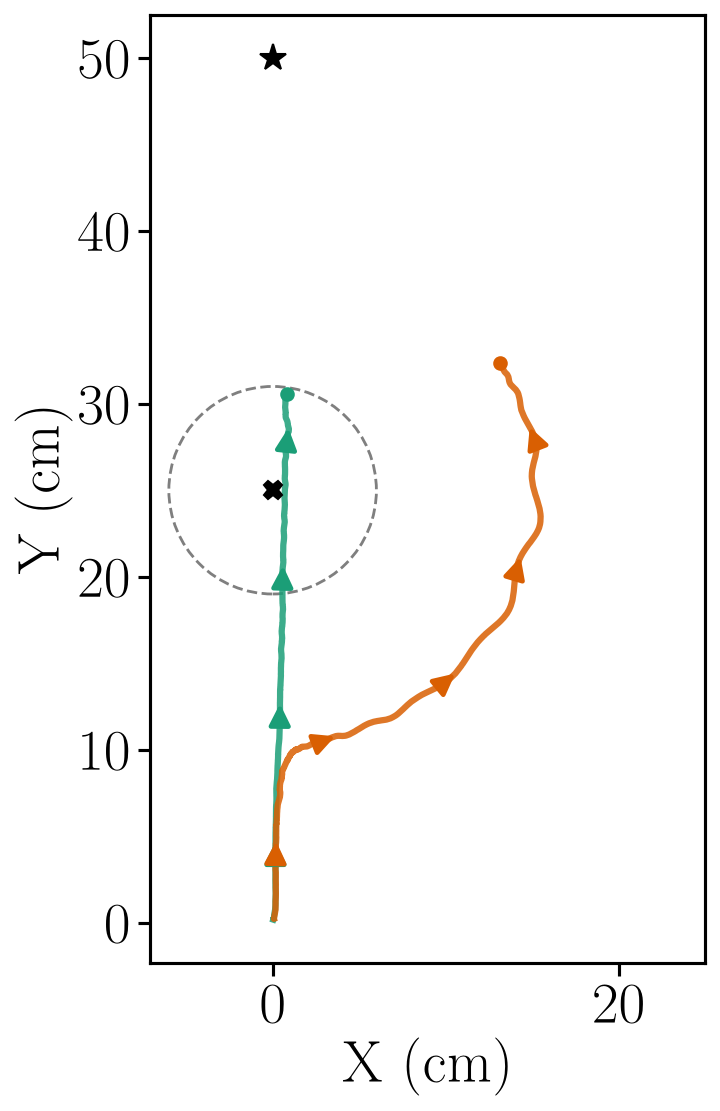

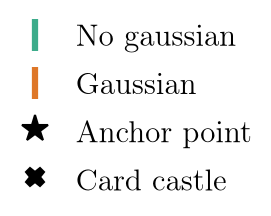

In [7]:
if runs_c:
    plot_tip_trajectory(runs_c, cfg_c, 'card_castle', obstacle_label='card castle')